# Интеграция пользовательского корректора в пайплайн

Пример для Manuscript OCR 0.1.13 с [Yandex Speller](https://yandex.ru/dev/speller/doc/ru/reference/checkText).

Подключим внешний сервис через собственный класс корректора. Он получает страницу с распознанным текстом, исправляет слова и возвращает обновлённую страницу. В этом примере текст слов отправляется в Yandex Speller через HTTP API.

## 1. Установка


In [1]:
%pip install "manuscript-ocr==0.1.13" requests



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Пользовательский корректор

Пайплайн вызывает метод `predict(page, image=None)` и ожидает `Page` в ответ. Наследоваться от базового класса необязательно.

`correction_levels` задаёт уровни, на которых исправляется текст. Здесь выбираем слова, поскольку используем TRBA. Если распознаватель записывает текст в строки, передайте `correction_levels=["line"]`.

Исправления применяются с конца текста, чтобы замены не сдвигали позиции следующих ошибок. При сетевой ошибке корректор сохраняет исходный текст и выдаёт предупреждение.


In [2]:
import warnings

import requests
from manuscript.data import Page, TextRegion


class YandexSpellerCorrector:
    """Адаптер сервиса: обязательный метод predict принимает и возвращает Page."""

    SPELLER_URL = "https://speller.yandex.net/services/spellservice.json/checkText"

    def __init__(self, lang="ru", timeout=5.0, correction_levels=("word",)):
        if (not isinstance(correction_levels, (list, tuple)) or not correction_levels
                or any(level not in ("word", "line", "block") for level in correction_levels)):
            raise ValueError("correction_levels: выберите word, line или block")
        self.lang = lang
        self.timeout = timeout
        # Уровни проверяет сам корректор: пайплайн передаёт ему страницу целиком.
        self.correction_levels = tuple(correction_levels)
        # Здесь можно загрузить свою модель или настроить клиент другого сервиса.
        self.session = requests.Session()

    def predict(self, page: Page, image=None) -> Page:
        # page содержит распознанный текст; image — необязательный исходный снимок.
        # Здесь изображение не нужно. Копия сохраняет входную страницу без изменений.
        result = page.clone()
        # Одинаковые слова проверяем один раз за вызов.
        corrected = {}
        # Обходим дерево, но исправляем только непустой текст выбранных уровней.
        # Родителей, геометрию и порядок элементов не меняем.
        for element in result.descendants:
            if (isinstance(element, TextRegion)
                    and element.type in self.correction_levels and element.text):
                if element.text not in corrected:
                    corrected[element.text] = self._correct_text(element.text)
                element.text = corrected[element.text]
        # Верните именно Page: следующий этап пайплайна ожидает этот объект.
        return result

    def _correct_text(self, text):
        # Замените реализацию вызовом своего корректора: строка на вход, строка на выход.
        try:
            response = self.session.post(
                self.SPELLER_URL,
                data={"text": text, "lang": self.lang},
                timeout=self.timeout,
            )
            response.raise_for_status()
            fixes = response.json()
        except (requests.RequestException, ValueError) as exc:
            warnings.warn(f"Yandex Speller: текст оставлен без исправлений ({exc})", stacklevel=2)
            return text

        corrected = text
        # Идём справа налево: длина замены не влияет на позиции оставшихся ошибок.
        for fix in sorted(fixes, key=lambda item: item["pos"], reverse=True):
            suggestions = fix.get("s") or []
            if suggestions:
                start = fix["pos"]
                end = start + fix["len"]
                corrected = corrected[:start] + suggestions[0] + corrected[end:]
        return corrected


## 3. Изображение

Используем полную страницу `example/images/full/img5.jpeg`.


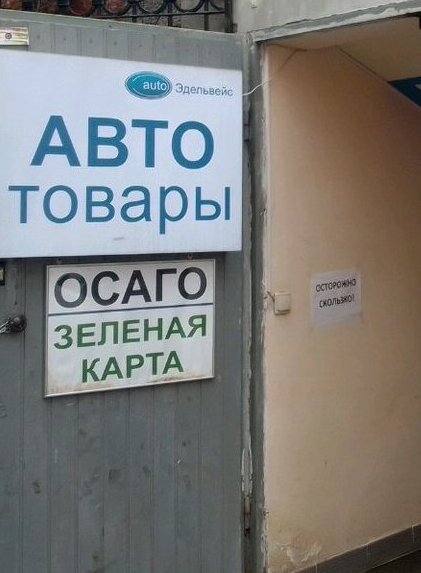

In [3]:
from pathlib import Path
from PIL import Image
from IPython.display import display

PROJECT_DIR = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file()),
    Path.cwd(),
)
image_path = PROJECT_DIR / "example/images/full/img5.jpeg"
if not image_path.exists():
    from urllib.request import urlretrieve
    image_path.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(
        "https://raw.githubusercontent.com/konstantinkozhin/manuscript-ocr/"
        "4193d8a613a7cfdec6a68cd2cdbb88b351f63964/example/images/img5.jpeg",
        image_path,
    )

image = Image.open(image_path).convert("RGB")
display(image)


## 4. Подключение к пайплайну

EAST находит слова, `SimpleSorting` определяет порядок и собирает строки, а TRBA распознаёт слова. Последним этапом работает наш корректор.


In [4]:
from manuscript import Pipeline
from manuscript.detectors import EAST
from manuscript.layouts import SimpleSorting
from manuscript.recognizers import TRBA
from manuscript.utils.visualization import visualize_page

pipeline = Pipeline(
    detector=EAST(weights="east_50_g1", device="cpu"),
    layout=SimpleSorting(),
    recognizer=TRBA(weights="trba_lite_g1", device="cpu"),
    corrector=YandexSpellerCorrector(correction_levels=["word"]),  # Наш корректор.
)
result = pipeline.predict(image)  # Пайплайн возвращает словарь результатов.
page = result["page"]

print(page.get_text())
display(visualize_page(image, page, max_size=1440, upscale=True))


AttributeError: 'dict' object has no attribute 'get_text'